# EDA – Superstore Sales Dataset (Đề tài 1)
**Mục tiêu:** hiểu dữ liệu bán lẻ Superstore, kiểm tra chất lượng, thống kê – tổng hợp và trực quan hóa
làm nền cho dashboard Streamlit 5 page.

Nội dung:
1. Mô tả dữ liệu (nguồn, số dòng/cột, ý nghĩa, kiểu biến)
2. Khám phá & xử lý dữ liệu: thiếu, trùng, ngoại lệ, thống kê mô tả, lọc, groupby, pivot table
3. Trực quan hóa: so sánh · phân phối · xu hướng thời gian · grouped/stacked
4. Insight & đề xuất

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", font_scale=1.0)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
REGION_COLORS = dict(zip(["West", "East", "Central", "South"], PALETTE))
CATEGORY_COLORS = dict(zip(["Technology", "Furniture", "Office Supplies"], PALETTE))
SEGMENT_COLORS = dict(zip(["Consumer", "Corporate", "Home Office"], PALETTE))
money = mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K" if abs(x) >= 1e3 else f"${x:,.0f}")

## 1. Mô tả dữ liệu
- **Nguồn:** Kaggle – [Superstore Dataset](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final), dữ liệu bán lẻ
  đồ nội thất, văn phòng phẩm, thiết bị công nghệ tại Mỹ giai đoạn 2014–2017.
- **File:** `data/superstore.csv`, mã hóa **latin-1**, cột ngày dạng **tháng/ngày/năm**.
- Mỗi dòng là **một sản phẩm trong một đơn hàng** (một đơn có thể có nhiều dòng).

In [2]:
df = pd.read_csv("data/superstore.csv", encoding="latin-1")
print(f"Số dòng: {df.shape[0]:,} | Số cột: {df.shape[1]}")
df.head()

Số dòng: 9,994 | Số cột: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [4]:
meaning = {
    "Row ID": "Số thứ tự dòng", "Order ID": "Mã đơn hàng", "Order Date": "Ngày đặt hàng",
    "Ship Date": "Ngày giao hàng", "Ship Mode": "Hình thức giao hàng", "Customer ID": "Mã khách hàng",
    "Customer Name": "Tên khách hàng", "Segment": "Phân khúc khách hàng", "Country": "Quốc gia",
    "City": "Thành phố", "State": "Bang", "Postal Code": "Mã bưu chính", "Region": "Khu vực (4 vùng)",
    "Product ID": "Mã sản phẩm", "Category": "Danh mục", "Sub-Category": "Danh mục con",
    "Product Name": "Tên sản phẩm", "Sales": "Doanh thu (USD)", "Quantity": "Số lượng",
    "Discount": "Tỷ lệ chiết khấu", "Profit": "Lợi nhuận (USD)",
}
kind = {"Order Date": "Thời gian", "Ship Date": "Thời gian", "Sales": "Số – liên tục",
        "Profit": "Số – liên tục", "Discount": "Số – liên tục", "Quantity": "Số – rời rạc",
        "Row ID": "Định danh", "Order ID": "Định danh", "Customer ID": "Định danh",
        "Product ID": "Định danh", "Postal Code": "Phân loại (mã)", "Customer Name": "Định danh"}
desc = pd.DataFrame({
    "Ý nghĩa": pd.Series(meaning),
    "Kiểu pandas": df.dtypes.astype(str),
    "Loại biến": pd.Series({c: kind.get(c, "Phân loại") for c in df.columns}),
    "Số giá trị khác nhau": df.nunique(),
    "Ví dụ": df.iloc[0].astype(str),
})
desc

,Ý nghĩa,Kiểu pandas,Loại biến,Số giá trị khác nhau,Ví dụ
Row ID,Số thứ tự dòng,int64,Định danh,9994,1
Order ID,Mã đơn hàng,str,Định danh,5009,CA-2016-152156
Order Date,Ngày đặt hàng,str,Thời gian,1237,11/8/2016
Ship Date,Ngày giao hàng,str,Thời gian,1334,11/11/2016
Ship Mode,Hình thức giao hàng,str,Phân loại,4,Second Class
Customer ID,Mã khách hàng,str,Định danh,793,CG-12520
Customer Name,Tên khách hàng,str,Định danh,793,Claire Gute
Segment,Phân khúc khách hàng,str,Phân loại,3,Consumer
Country,Quốc gia,str,Phân loại,1,United States
City,Thành phố,str,Phân loại,531,Henderson


**Xử lý kiểu dữ liệu:** `Order Date`, `Ship Date` đang là chuỗi → chuyển sang `datetime` theo định dạng `%m/%d/%Y`.
Thêm các cột phái sinh phục vụ phân tích: năm, tháng, số ngày giao hàng, biên lợi nhuận.

In [5]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Month Num"] = df["Order Date"].dt.month
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Margin"] = df["Profit"] / df["Sales"]
print("Giai đoạn:", df["Order Date"].min().date(), "→", df["Order Date"].max().date())
print(f"Số đơn hàng: {df['Order ID'].nunique():,} | Khách hàng: {df['Customer ID'].nunique():,} | "
      f"Mã sản phẩm: {df['Product ID'].nunique():,} | Bang: {df['State'].nunique()} | Thành phố: {df['City'].nunique()}")
print("Country:", df["Country"].unique())

Giai đoạn: 2014-01-03 → 2017-12-30
Số đơn hàng: 5,009 | Khách hàng: 793 | Mã sản phẩm: 1,862 | Bang: 49 | Thành phố: 531
Country: <ArrowStringArray>
['United States']
Length: 1, dtype: str


## 2. Khám phá & xử lý dữ liệu (EDA)
### 2.1 Dữ liệu thiếu và trùng lặp

In [6]:
missing = df.isna().sum()
print("Tổng số ô thiếu:", missing.sum())
print("Số dòng trùng lặp hoàn toàn:", df.duplicated().sum())
print("Số dòng trùng (bỏ Row ID):", df.drop(columns="Row ID").duplicated().sum())
print("Ship Date < Order Date:", (df["Ship Days"] < 0).sum())
print("Sales <= 0:", (df["Sales"] <= 0).sum(), "| Quantity <= 0:", (df["Quantity"] <= 0).sum())

Tổng số ô thiếu: 0
Số dòng trùng lặp hoàn toàn: 0
Số dòng trùng (bỏ Row ID): 1
Ship Date < Order Date: 0
Sales <= 0: 0 | Quantity <= 0: 0


→ Dữ liệu **không có giá trị thiếu**, không có ngày giao trước ngày đặt, doanh thu và số lượng đều dương.
Nếu có vài dòng trùng khi bỏ `Row ID` (cùng đơn, cùng sản phẩm) thì đó có thể là các lần quét hàng tách dòng
hợp lệ nên **giữ lại**. `Country` chỉ có một giá trị (United States) nên không dùng để phân tích.

### 2.2 Thống kê mô tả

In [7]:
num_cols = ["Sales", "Quantity", "Discount", "Profit", "Ship Days"]
df[num_cols].describe().T.assign(skew=df[num_cols].skew())

,count,mean,std,min,25%,50%,75%,max,skew
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48",12.97
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00,1.28
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80,1.68
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98",7.56
Ship Days,"9,994.00",3.96,1.75,0.00,3.00,4.00,5.00,7.00,-0.42


In [8]:
df.select_dtypes(exclude=["number", "datetime"]).describe().T

,count,unique,top,freq
Order ID,9994,5009,CA-2017-100111,14
Ship Mode,9994,4,Standard Class,5968
Customer ID,9994,793,WB-21850,37
Customer Name,9994,793,William Brown,37
Segment,9994,3,Consumer,5191
Country,9994,1,United States,9994
City,9994,531,New York City,915
State,9994,49,California,2001
Region,9994,4,West,3203
Product ID,9994,1862,OFF-PA-10001970,19


### 2.3 Ngoại lệ (outlier) – phương pháp IQR

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"Q1": q1, "Q3": q3, "Ngưỡng dưới": lo, "Ngưỡng trên": hi,
                      "Số ngoại lệ": ((s < lo) | (s > hi)).sum(),
                      "Tỷ lệ (%)": ((s < lo) | (s > hi)).mean() * 100})
pd.DataFrame({c: iqr_outliers(df[c]) for c in ["Sales", "Profit", "Quantity", "Discount"]}).T

,Q1,Q3,Ngưỡng dưới,Ngưỡng trên,Số ngoại lệ,Tỷ lệ (%)
Sales,17.28,209.94,-271.71,498.93,"1,167.00",11.68
Profit,1.73,29.36,-39.72,70.82,"1,881.00",18.82
Quantity,2.00,5.00,-2.50,9.50,170.00,1.70
Discount,0.00,0.20,-0.30,0.50,856.00,8.57


In [10]:
print("5 giao dịch doanh thu lớn nhất:")
display(df.nlargest(5, "Sales")[["Order Date", "Product Name", "Category", "Sales", "Discount", "Profit"]])
print("5 giao dịch lỗ nặng nhất:")
display(df.nsmallest(5, "Profit")[["Order Date", "Product Name", "Category", "Sales", "Discount", "Profit"]])

5 giao dịch doanh thu lớn nhất:


,Order Date,Product Name,Category,Sales,Discount,Profit
2697,2014-03-18,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48",0.50,"-1,811.08"
6826,2016-10-02,Canon imageCLASS 2200 Advanced Copier,Technology,"17,499.95",0.00,"8,399.98"
8153,2017-03-23,Canon imageCLASS 2200 Advanced Copier,Technology,"13,999.96",0.00,"6,719.98"
2623,2017-10-22,Canon imageCLASS 2200 Advanced Copier,Technology,"11,199.97",0.20,"3,919.99"
4190,2017-11-17,Canon imageCLASS 2200 Advanced Copier,Technology,"10,499.97",0.00,"5,039.99"


5 giao dịch lỗ nặng nhất:


,Order Date,Product Name,Category,Sales,Discount,Profit
7772,2016-11-25,Cubify CubeX 3D Printer Double Head Print,Technology,"4,499.98",0.70,"-6,599.98"
683,2017-11-04,Cubify CubeX 3D Printer Triple Head Print,Technology,"7,999.98",0.50,"-3,839.99"
9774,2014-07-26,GBC DocuBind P400 Electric Binding System,Office Supplies,"2,177.58",0.80,"-3,701.89"
3011,2017-04-17,Lexmark MX611dhe Monochrome Laser Printer,Technology,"2,549.99",0.70,"-3,399.98"
4991,2017-12-07,Ibico EPK-21 Electric Binding System,Office Supplies,"1,889.99",0.80,"-2,929.48"


→ `Sales` và `Profit` **lệch mạnh** (skew lớn), khoảng 12–19% dòng là ngoại lệ theo IQR.
Đây là các đơn hàng giá trị lớn có thật (máy photocopy, máy đóng sách, bàn ghế…) chứ không phải lỗi nhập liệu,
nên **không loại bỏ**; khi trực quan hóa phân phối sẽ dùng thang log hoặc boxplot để đọc rõ hơn.
Các khoản lỗ lớn nhất đều đi kèm **chiết khấu cao (≥ 0.5)**.

### 2.4 Lọc dữ liệu theo điều kiện

In [11]:
loss = df[df["Profit"] < 0]
print(f"Số dòng thua lỗ: {len(loss):,} ({len(loss)/len(df):.1%}) – tổng lỗ ${loss['Profit'].sum():,.0f}")
high_disc = df[df["Discount"] >= 0.5]
print(f"Dòng có chiết khấu ≥ 50%: {len(high_disc):,} – lợi nhuận TB ${high_disc['Profit'].mean():,.1f}/dòng")
tech_west_2017 = df[(df["Category"] == "Technology") & (df["Region"] == "West") & (df["Year"] == 2017)]
print(f"Technology – West – 2017: {len(tech_west_2017)} dòng, doanh thu ${tech_west_2017['Sales'].sum():,.0f}")

Số dòng thua lỗ: 1,871 (18.7%) – tổng lỗ $-156,131
Dòng có chiết khấu ≥ 50%: 922 – lợi nhuận TB $-105.3/dòng
Technology – West – 2017: 213 dòng, doanh thu $95,959


### 2.5 GroupBy – tổng hợp

In [12]:
def summary(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                           Orders=("Order ID", "nunique"), Quantity=("Quantity", "sum"),
                           AvgDiscount=("Discount", "mean"))
    g["Margin"] = g["Profit"] / g["Sales"]
    g["Share"] = g["Sales"] / g["Sales"].sum()
    return g.sort_values("Sales", ascending=False)
summary("Region")

,Sales,Profit,Orders,Quantity,AvgDiscount,Margin,Share
Region,,,,,,,
West,"725,457.82","108,418.45",1611,12266,0.11,0.15,0.32
East,"678,781.24","91,522.78",1401,10618,0.15,0.13,0.30
Central,"501,239.89","39,706.36",1175,8780,0.24,0.08,0.22
South,"391,721.91","46,749.43",822,6209,0.15,0.12,0.17


In [13]:
summary('Category')

,Sales,Profit,Orders,Quantity,AvgDiscount,Margin,Share
Category,,,,,,,
Technology,"836,154.03","145,454.95",1544,6939,0.13,0.17,0.36
Furniture,"741,999.80","18,451.27",1764,8028,0.17,0.02,0.32
Office Supplies,"719,047.03","122,490.80",3742,22906,0.16,0.17,0.31


In [14]:
summary('Segment')

,Sales,Profit,Orders,Quantity,AvgDiscount,Margin,Share
Segment,,,,,,,
Consumer,"1,161,401.34","134,119.21",2586,19521,0.16,0.12,0.51
Corporate,"706,146.37","91,979.13",1514,11608,0.16,0.13,0.31
Home Office,"429,653.15","60,298.68",909,6744,0.15,0.14,0.19


In [15]:
summary('Sub-Category')

,Sales,Profit,Orders,Quantity,AvgDiscount,Margin,Share
Sub-Category,,,,,,,
Phones,"330,007.05","44,515.73",814,3289,0.15,0.13,0.14
Chairs,"328,449.10","26,590.17",576,2356,0.17,0.08,0.14
Storage,"223,843.61","21,278.83",777,3158,0.07,0.10,0.10
Tables,"206,965.53","-17,725.48",307,1241,0.26,-0.09,0.09
Binders,"203,412.73","30,221.76",1316,5974,0.37,0.15,0.09
Machines,"189,238.63","3,384.76",112,440,0.31,0.02,0.08
Accessories,"167,380.32","41,936.64",718,2976,0.08,0.25,0.07
Copiers,"149,528.03","55,617.82",68,234,0.16,0.37,0.07
Bookcases,"114,880.00","-3,472.56",224,868,0.21,-0.03,0.05


In [16]:
yearly = summary("Year").sort_index()
yearly["Growth"] = yearly["Sales"].pct_change()
yearly

,Sales,Profit,Orders,Quantity,AvgDiscount,Margin,Share,Growth
Year,,,,,,,,
2014,"484,247.50","49,543.97",969,7581,0.16,0.10,0.21,NaN
2015,"470,532.51","61,618.60",1038,7979,0.16,0.13,0.20,-0.03
2016,"609,205.60","81,795.17",1315,9837,0.15,0.13,0.27,0.29
2017,"733,215.26","93,439.27",1687,12476,0.16,0.13,0.32,0.20


### 2.6 Pivot table

In [17]:
pivot_sales = df.pivot_table(index="Category", columns="Region", values="Sales", aggfunc="sum",
                             margins=True, margins_name="Tổng")
pivot_sales

Region,Central,East,South,West,Tổng
Category,,,,,
Furniture,"163,797.16","208,291.20","117,298.68","252,612.74","741,999.80"
Office Supplies,"167,026.42","205,516.05","125,651.31","220,853.25","719,047.03"
Technology,"170,416.31","264,973.98","148,771.91","251,991.83","836,154.03"
Tổng,"501,239.89","678,781.24","391,721.91","725,457.82","2,297,200.86"


In [18]:
pivot_margin = (df.pivot_table(index="Sub-Category", columns="Region", values="Profit", aggfunc="sum")
                / df.pivot_table(index="Sub-Category", columns="Region", values="Sales", aggfunc="sum"))
pivot_margin.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4)

Region,Central,East,South,West
Sub-Category,,,,
Accessories,21.4%,24.9%,25.7%,27.0%
Appliances,-11.2%,24.5%,21.1%,27.3%
Art,20.7%,25.4%,22.7%,25.8%
Binders,-1.8%,21.1%,10.5%,28.8%
Bookcases,-8.3%,-2.7%,12.3%,-4.6%
Chairs,7.7%,9.7%,14.6%,4.0%
Copiers,41.9%,32.0%,39.3%,38.8%
Envelopes,38.3%,41.4%,43.8%,46.4%
Fasteners,30.4%,32.2%,34.5%,29.8%


In [19]:
df.pivot_table(index="Year", columns="Category", values="Sales", aggfunc="sum")

Category,Furniture,Office Supplies,Technology
Year,,,
2014,"157,192.85","151,776.41","175,278.23"
2015,"170,518.24","137,233.46","162,780.81"
2016,"198,901.44","183,939.98","226,364.18"
2017,"215,387.27","246,097.17","271,730.81"


## 3. Trực quan hóa dữ liệu
### 3.1 Biểu đồ so sánh (bar) – doanh thu & lợi nhuận theo khu vực, danh mục con

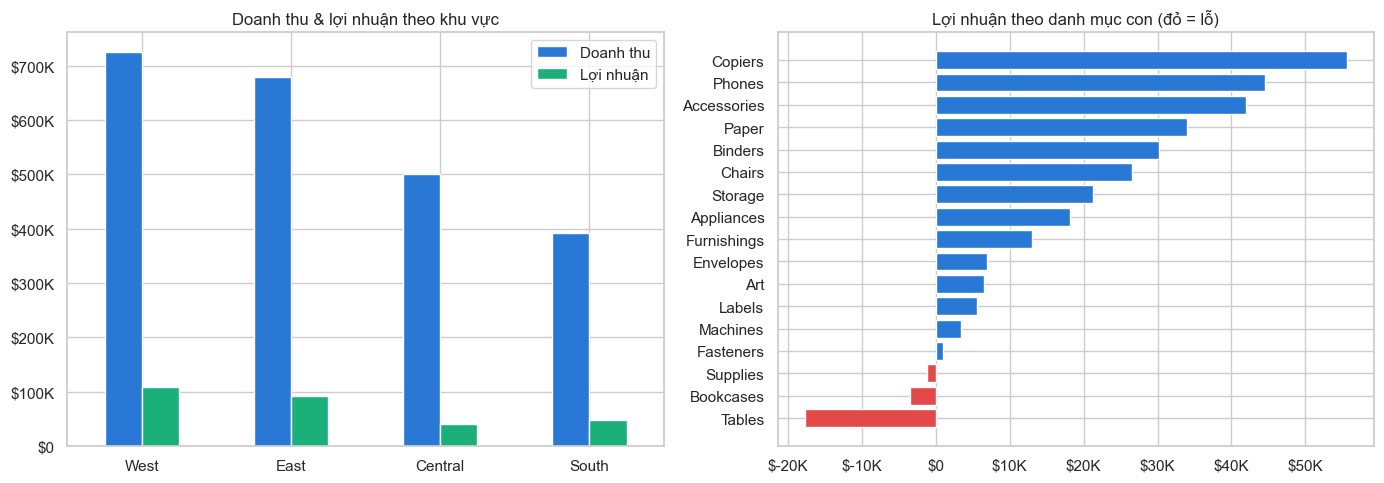

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
reg = summary("Region")
reg[["Sales", "Profit"]].plot.bar(ax=axes[0], color=["#2a78d6", "#1baf7a"], rot=0)
axes[0].set_title("Doanh thu & lợi nhuận theo khu vực"); axes[0].yaxis.set_major_formatter(money)
axes[0].set_xlabel(""); axes[0].legend(["Doanh thu", "Lợi nhuận"])
sub = summary("Sub-Category").sort_values("Profit")
axes[1].barh(sub.index, sub["Profit"], color=np.where(sub["Profit"] < 0, "#e34948", "#2a78d6"))
axes[1].set_title("Lợi nhuận theo danh mục con (đỏ = lỗ)"); axes[1].xaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()

**Nhận xét:** West dẫn đầu cả doanh thu (~$725K, 31.6%) lẫn lợi nhuận (~$108K); Central có doanh thu đứng thứ 3
nhưng biên lợi nhuận thấp nhất (7.9%). Ba danh mục con **Tables, Bookcases, Supplies** đang thua lỗ – riêng Tables lỗ
~$17.7K dù doanh thu hơn $200K; Copiers và Phones là hai nguồn lợi nhuận lớn nhất.

### 3.2 Biểu đồ phân phối (histogram / boxplot)

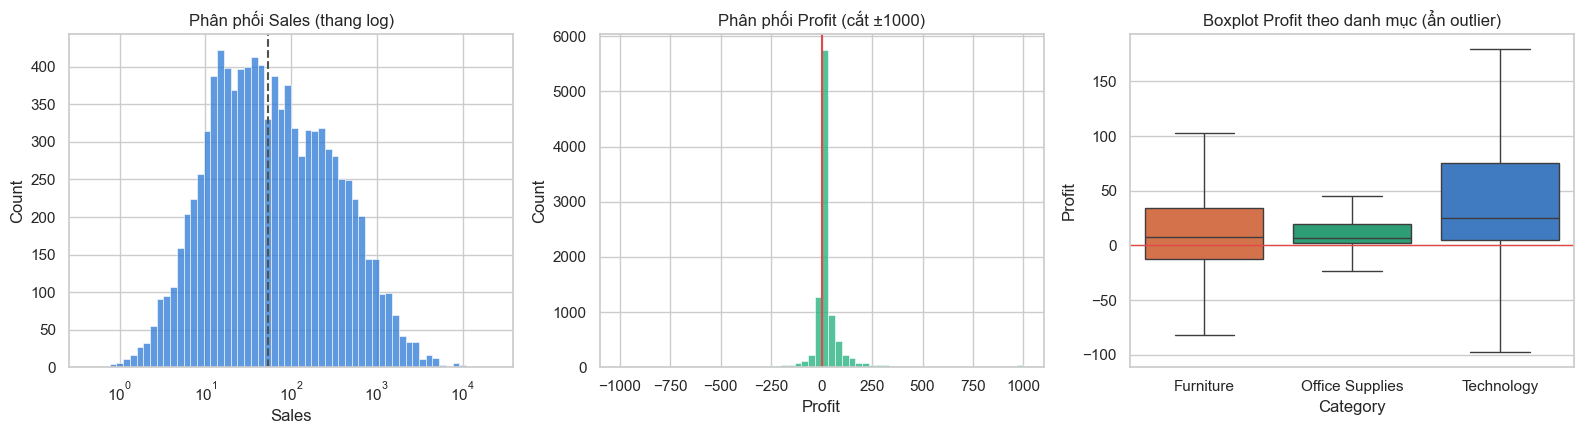

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df["Sales"], bins=60, log_scale=True, ax=axes[0], color="#2a78d6")
axes[0].axvline(df["Sales"].median(), ls="--", c="#52514e"); axes[0].set_title("Phân phối Sales (thang log)")
sns.histplot(df["Profit"].clip(-1000, 1000), bins=60, ax=axes[1], color="#1baf7a")
axes[1].axvline(0, c="#e34948"); axes[1].set_title("Phân phối Profit (cắt ±1000)")
sns.boxplot(data=df, x="Category", y="Profit", hue="Category", palette=CATEGORY_COLORS, ax=axes[2],
            showfliers=False, legend=False)
axes[2].axhline(0, c="#e34948", lw=1); axes[2].set_title("Boxplot Profit theo danh mục (ẩn outlier)")
plt.tight_layout(); plt.show()

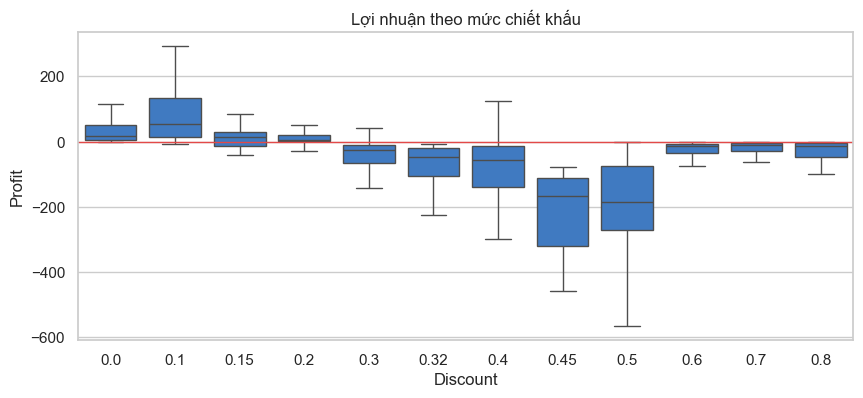

Discount,0.00,0.10,0.15,0.20,0.30,0.32,0.40,0.45,0.50,0.60,0.70,0.80
mean,66.90,96.10,27.30,24.70,-45.70,-88.60,-111.90,-226.60,-310.70,-43.10,-95.90,-101.80
count,"4,798.00",94.00,52.00,"3,657.00",227.00,27.00,206.00,11.00,66.00,138.00,418.00,300.00


In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="Discount", y="Profit", color="#2a78d6", showfliers=False, ax=ax)
ax.axhline(0, c="#e34948", lw=1); ax.set_title("Lợi nhuận theo mức chiết khấu"); plt.show()
df.groupby("Discount")["Profit"].agg(["mean", "count"]).round(1).T

**Nhận xét:** Doanh thu mỗi dòng lệch phải mạnh – trung vị chỉ ~$54 trong khi trung bình ~$230. Lợi nhuận tập trung
quanh 0–30$ nhưng có đuôi âm dài. Từ **chiết khấu 30% trở lên, lợi nhuận trung bình chuyển sang âm**;
Furniture có hộp lợi nhuận thấp nhất và trải xuống vùng âm nhiều nhất.

### 3.3 Biểu đồ xu hướng theo thời gian

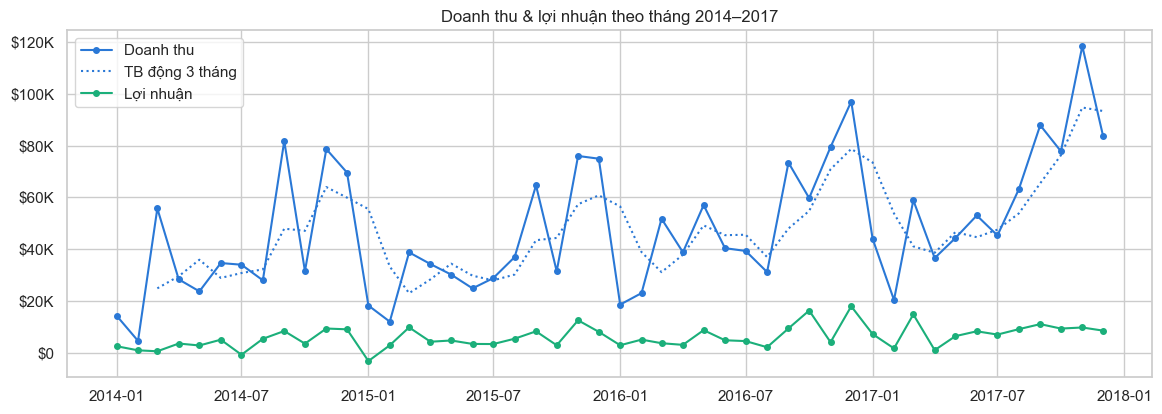

In [23]:
monthly = df.set_index("Order Date")[["Sales", "Profit"]].resample("MS").sum()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=4, c="#2a78d6", label="Doanh thu")
ax.plot(monthly.index, monthly["Sales"].rolling(3).mean(), ls=":", c="#2a78d6", label="TB động 3 tháng")
ax.plot(monthly.index, monthly["Profit"], marker="o", ms=4, c="#1baf7a", label="Lợi nhuận")
ax.yaxis.set_major_formatter(money); ax.legend(); ax.set_title("Doanh thu & lợi nhuận theo tháng 2014–2017")
plt.show()

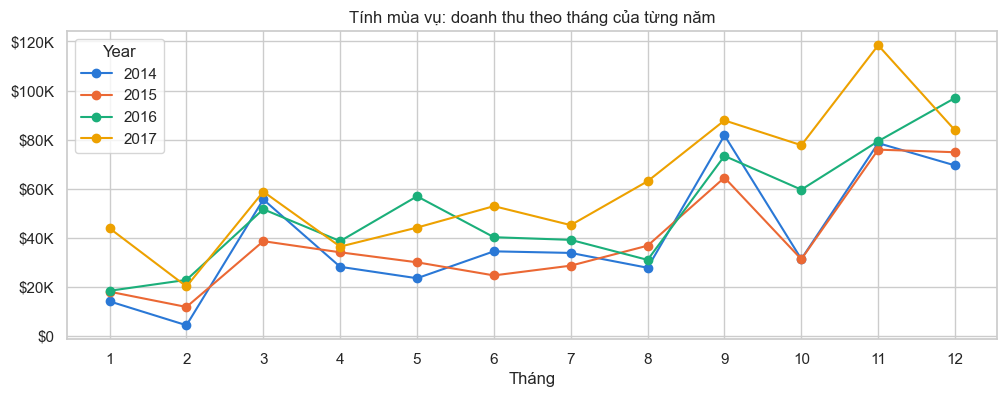

Quý 4 chiếm 38.2% doanh thu cả giai đoạn


In [24]:
season = df.pivot_table(index="Month Num", columns="Year", values="Sales", aggfunc="sum")
ax = season.plot(figsize=(12, 4), marker="o", color=PALETTE)
ax.yaxis.set_major_formatter(money); ax.set_xticks(range(1, 13)); ax.set_xlabel("Tháng")
ax.set_title("Tính mùa vụ: doanh thu theo tháng của từng năm"); plt.show()
q4_share = df[df["Month Num"] >= 10]["Sales"].sum() / df["Sales"].sum()
print(f"Quý 4 chiếm {q4_share:.1%} doanh thu cả giai đoạn")

**Nhận xét:** Doanh thu có xu hướng **tăng** (2014 → 2017 tăng ~51%, riêng 2015 giảm nhẹ 2.8%), với tính mùa vụ
rõ rệt: đỉnh vào **tháng 9, 11, 12**, đáy vào **tháng 1–2**. Quý 4 chiếm khoảng 38% doanh thu → cần chuẩn bị tồn kho,
nhân sự và chiến dịch marketing từ tháng 9.

### 3.4 Biểu đồ tổng hợp (grouped / stacked)

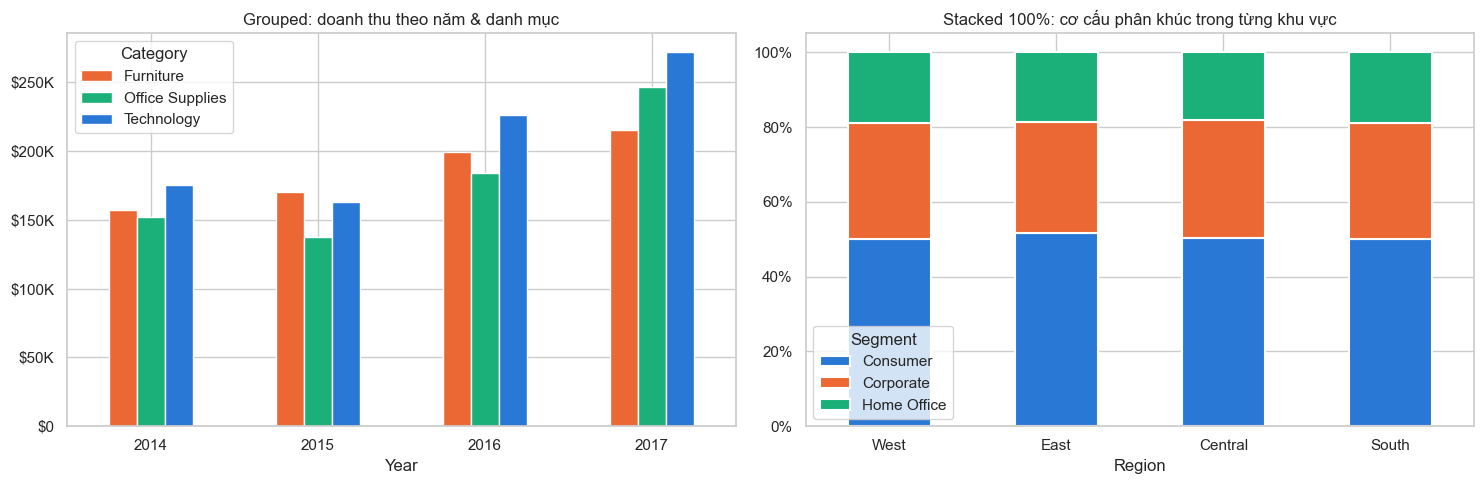

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cy = df.pivot_table(index="Year", columns="Category", values="Sales", aggfunc="sum")
cy.plot.bar(ax=axes[0], color=[CATEGORY_COLORS[c] for c in cy.columns], rot=0)
axes[0].yaxis.set_major_formatter(money); axes[0].set_title("Grouped: doanh thu theo năm & danh mục")
rs = df.pivot_table(index="Region", columns="Segment", values="Sales", aggfunc="sum")
rs = rs.loc[rs.sum(axis=1).sort_values(ascending=False).index]
(rs.div(rs.sum(axis=1), axis=0)).plot.bar(stacked=True, ax=axes[1], rot=0,
    color=[SEGMENT_COLORS[c] for c in rs.columns], edgecolor="white", linewidth=1.5)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Stacked 100%: cơ cấu phân khúc trong từng khu vực")
plt.tight_layout(); plt.show()

**Nhận xét:** Cả 3 danh mục đều tăng qua các năm, Technology dẫn đầu doanh thu ở hầu hết các năm. Cơ cấu phân khúc
khá đồng đều giữa các vùng – **Consumer luôn chiếm khoảng một nửa** doanh thu, nên khác biệt giữa các khu vực đến từ
quy mô và lợi nhuận chứ không phải tập khách hàng.

### 3.5 Bổ sung – heatmap biên lợi nhuận Danh mục con × Khu vực

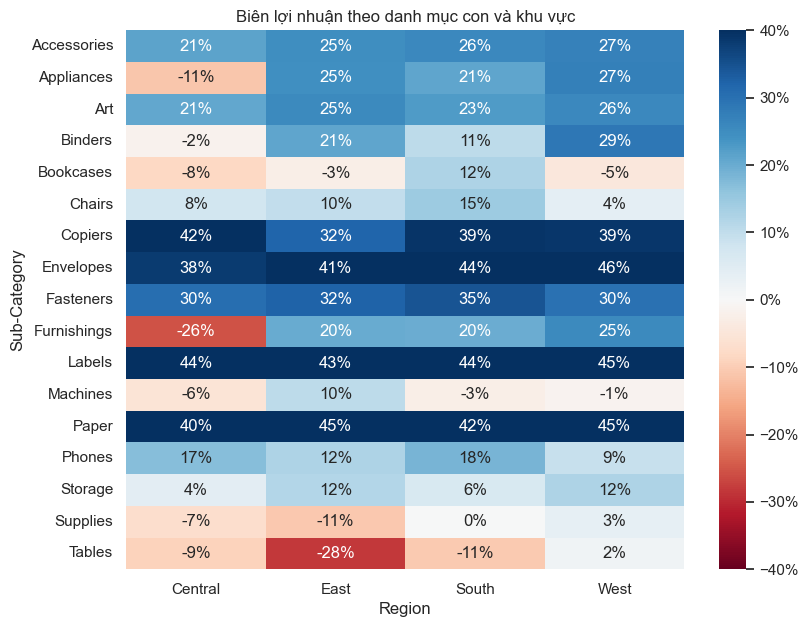

In [26]:
plt.figure(figsize=(9, 7))
sns.heatmap(pivot_margin, annot=True, fmt=".0%", cmap="RdBu", center=0, vmin=-0.4, vmax=0.4,
            cbar_kws={"format": mtick.PercentFormatter(1.0)})
plt.title("Biên lợi nhuận theo danh mục con và khu vực"); plt.show()

## 4. Insight & đề xuất
| # | Phát hiện | Gợi ý quyết định |
|---|---|---|
| 1 | Tổng doanh thu ~$2.30M, lợi nhuận ~$286K (biên 12.5%) từ 5.009 đơn, 793 khách hàng | Theo dõi biên LN song song doanh thu |
| 2 | Doanh thu tăng ~51% từ 2014 → 2017; Q4 chiếm khoảng 38% doanh thu | Lập kế hoạch tồn kho & marketing theo mùa từ tháng 9 |
| 3 | West & East chiếm ~61% doanh thu; Central biên LN thấp nhất (7.9%) | Rà soát chính sách chiết khấu tại Central |
| 4 | Texas, Ohio, Pennsylvania, Illinois lỗ nặng nhất | Giới hạn chiết khấu tối đa ~20% ở các bang này |
| 5 | Furniture doanh thu cao nhưng biên chỉ 2.5%; Tables, Bookcases, Supplies thua lỗ | Tăng giá/giảm khuyến mãi bàn & kệ sách, xem lại chi phí vận chuyển |
| 6 | Chiết khấu ≥ 30% → lợi nhuận trung bình âm | Đặt ngưỡng phê duyệt cho chiết khấu > 20% |
| 7 | Copiers, Phones, Accessories, Paper sinh lời cao | Ưu tiên quảng bá & bán chéo các nhóm này |